# Agreement Analysis

Analyze agreement between models and reference labels.

In [1]:
# Import pandas for working with tabular data
import pandas as pd

# Import matplotlib for visualizations
import matplotlib.pyplot as plt

# Load the MHIST annotation file
annotations_path = "../data/raw/annotations.csv"

df = pd.read_csv(annotations_path)

# Display the first five rows
display(df.head())

# Display column names
print("Columns:", df.columns.tolist())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

,Image Name,Majority Vote Label,Number of Annotators who Selected SSA (Out of 7),Partition
0,MHIST_aaa.png,SSA,6,train
1,MHIST_aab.png,HP,0,train
2,MHIST_aac.png,SSA,5,train
3,MHIST_aae.png,HP,1,train
4,MHIST_aaf.png,SSA,5,train


Columns: ['Image Name', 'Majority Vote Label', 'Number of Annotators who Selected SSA (Out of 7)', 'Partition']
Dataset shape: (3152, 4)

Missing values:
Image Name                                          0
Majority Vote Label                                 0
Number of Annotators who Selected SSA (Out of 7)    0
Partition                                           0
dtype: int64


In [2]:

# Column containing the number of annotators who selected SSA
ssa_votes_col = "Number of Annotators who Selected SSA (Out of 7)"

# Count how many annotators selected SSA for each image
df["SSA_votes"] = df[ssa_votes_col]

# Calculate how many selected HP
df["HP_votes"] = 7 - df["SSA_votes"]

# Calculate the difference between the two vote counts
df["Vote_difference"] = abs(df["SSA_votes"] - df["HP_votes"])

# Calculate the proportion of annotators who agreed with the majority label
df["Agreement_percentage"] = (df[["SSA_votes", "HP_votes"]].max(axis=1) / 7) * 100

# Display the first few rows
display(df[["Image Name","Majority Vote Label","HP_votes","SSA_votes","Vote_difference","Agreement_percentage"]].head(10))

,Image Name,Majority Vote Label,HP_votes,SSA_votes,Vote_difference,Agreement_percentage
0,MHIST_aaa.png,SSA,1,6,5,85.714286
1,MHIST_aab.png,HP,7,0,7,100.000000
2,MHIST_aac.png,SSA,2,5,3,71.428571
3,MHIST_aae.png,HP,6,1,5,85.714286
4,MHIST_aaf.png,SSA,2,5,3,71.428571
5,MHIST_aag.png,HP,5,2,3,71.428571
6,MHIST_aah.png,HP,5,2,3,71.428571
7,MHIST_aai.png,HP,4,3,1,57.142857
8,MHIST_aaj.png,HP,7,0,7,100.000000
9,MHIST_aak.png,HP,5,2,3,71.428571


                          mean     median        std  count
Majority Vote Label                                        
HP                   83.606449  85.714286  14.846315   2162
SSA                  82.193362  85.714286  16.553140    990


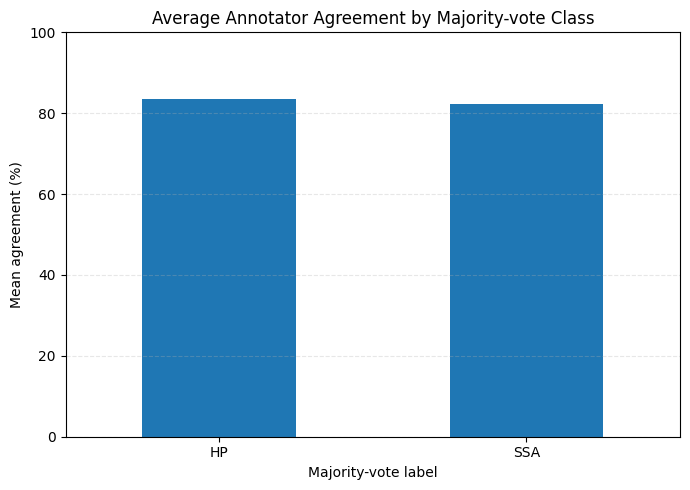

In [4]:

# Calculate average majority-vote agreement for each class
class_agreement = df.groupby("Majority Vote Label")["Agreement_percentage"].agg(["mean", "median", "std", "count"])
print(class_agreement)

# Plot average agreement by class
plt.figure(figsize=(7, 5))
class_agreement["mean"].plot(kind="bar")

plt.title("Average Annotator Agreement by Majority-vote Class")
plt.xlabel("Majority-vote label")
plt.ylabel("Mean agreement (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/figures/annotator_agreement_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:

# Check variables currently available in the notebook
print("Available prediction-related variables:")

for name in [
    "all_labels",
    "all_predictions",
    "all_probabilities",
    "model",
    "models",
    "trained_models",
    "test_dataset",
    "test_loader"
]:
    print(f"{name}: {name in globals()}")

Available prediction-related variables:
all_labels: False
all_predictions: False
all_probabilities: False
model: False
models: False
trained_models: False
test_dataset: False
test_loader: False


In [6]:
import os

# Check the project folders
print("Current working directory:", os.getcwd())

for folder in ["../data", "../models", "../results", "../outputs"]:
    print(f"\nFolder: {folder}")

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            # Avoid printing too many nested files
            level = root.replace(folder, "").count(os.sep)
            if level > 2:
                dirs[:] = []
                continue

            for file in files:
                print(os.path.join(root, file))
    else:
        print("Folder not found")

Current working directory: c:\Users\DARPAN\Deep-learning-PBL-3\MHIST-Research\notebooks

Folder: ../data
../data\metadata\.gitkeep
../data\metadata\test_split.csv
../data\metadata\train_split.csv
../data\metadata\val_split.csv
../data\processed\.gitkeep
../data\raw\.gitkeep
../data\raw\annotations.csv
../data\raw\MD5SUMs.txt

Folder: ../models
../models\checkpoints\.gitkeep
../models\checkpoints\efficientnet_b0.pth
../models\checkpoints\mobilenetv3_small.pth
../models\checkpoints\mobilenet_v3_small.pth
../models\checkpoints\resnet18.pth
../models\checkpoints\shufflenet_v3_small.pth
../models\configs\.gitkeep

Folder: ../results
../results\inference_speed.csv
../results\model_comparison.csv
../results\model_efficiency.csv
../results\robustness_all_models.csv
../results\robustness_performance_drops.csv
../results\robustness_results.csv
../results\figures\.gitkeep
../results\figures\robustness_accuracy.png
../results\predictions\.gitkeep
../results\tables\.gitkeep

Folder: ../outputs
Fold

In [ ]:
import pandas as pd
import os

# Paths relative to the notebooks folder
results_path = "../results/tables"
annotations_path = "../data/raw/annotations.csv"

# List available result CSV files
for file in os.listdir(results_path):
    if file.endswith(".csv"):
        print("\n" + "=" * 50)
        print("File:", file)
        temp_df = pd.read_csv(os.path.join(results_path, file))
        print("Shape:", temp_df.shape)
        print("Columns:", temp_df.columns.tolist())
        display(temp_df.head(5))

# Inspect the original MHIST annotations
df = pd.read_csv(annotations_path)
print("\nAnnotation dataset shape:", df.shape)
print("Annotation columns:", df.columns.tolist())
display(df.head())

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load MHIST annotations
annotations_path = "../data/raw/annotations.csv"
df = pd.read_csv(annotations_path)

# Number of annotators who selected SSA
ssa_votes = df["Number of Annotators who Selected SSA (Out of 7)"]

# The remaining annotators voted for HP
df["HP_votes"] = 7 - ssa_votes
df["SSA_votes"] = ssa_votes

# Calculate the proportion of annotators agreeing
# with the majority-vote label
df["Agreement_percentage"] = (df[["HP_votes", "SSA_votes"]].max(axis=1) / 7) * 100

# Calculate the difference between SSA and HP votes
df["Vote_difference"] = abs(df["SSA_votes"] - df["HP_votes"])

# Display the calculated information
display(df[["Image Name","Majority Vote Label","HP_votes","SSA_votes","Vote_difference","Agreement_percentage",]].head(10))

print("Mean agreement:", round(df["Agreement_percentage"].mean(), 2), "%")
print("Median agreement:", round(df["Agreement_percentage"].median(), 2), "%")

,Image Name,Majority Vote Label,HP_votes,SSA_votes,Vote_difference,Agreement_percentage
0,MHIST_aaa.png,SSA,1,6,5,85.714286
1,MHIST_aab.png,HP,7,0,7,100.000000
2,MHIST_aac.png,SSA,2,5,3,71.428571
3,MHIST_aae.png,HP,6,1,5,85.714286
4,MHIST_aaf.png,SSA,2,5,3,71.428571
5,MHIST_aag.png,HP,5,2,3,71.428571
6,MHIST_aah.png,HP,5,2,3,71.428571
7,MHIST_aai.png,HP,4,3,1,57.142857
8,MHIST_aaj.png,HP,7,0,7,100.000000
9,MHIST_aak.png,HP,5,2,3,71.428571


Mean agreement: 83.16 %
Median agreement: 85.71 %


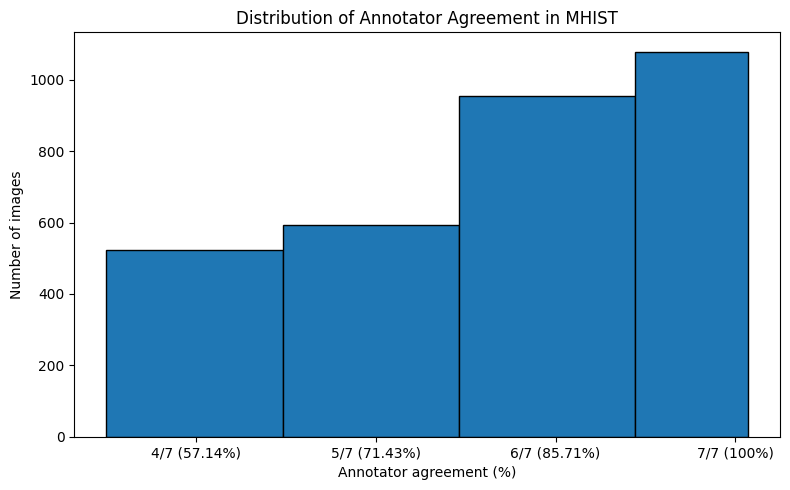

In [10]:
plt.figure(figsize=(8, 5))
agreement_levels = sorted(df["Agreement_percentage"].unique())
plt.hist(df["Agreement_percentage"],bins=[50, 64, 78, 92, 101],edgecolor="black")

plt.title("Distribution of Annotator Agreement in MHIST")
plt.xlabel("Annotator agreement (%)")
plt.ylabel("Number of images")
plt.xticks([57.14, 71.43, 85.71, 100],["4/7 (57.14%)", "5/7 (71.43%)","6/7 (85.71%)", "7/7 (100%)"])
plt.tight_layout()
plt.savefig("../results/figures/annotator_agreement_levels.png", dpi=300, bbox_inches="tight")
plt.show()